# Team 25 — Week 3: Modelling, Tuning & Interpretability

**Task:** predict hourly bike rentals (`cnt`) — UCI Bike Sharing Demand (ID 275), regression.
**Team:** Kishkenebayeva Altynay (Modelling & Report Lead) · Bakytkhanov Daulet (Feature Engineer) · Khamzin Daulet (Deployment Lead)

| Model | Role | Tuning |
| :-- | :-- | :-- |
| Linear Regression | Baseline | none |
| Random Forest | Intermediate 1 | `RandomizedSearchCV` → `GridSearchCV` |
| Gradient Boosting | Intermediate 2 | `RandomizedSearchCV` → `GridSearchCV` |
| XGBoost | Advanced | `RandomizedSearchCV` → `GridSearchCV` + early stopping |

**Protocol:** identical leakage-free `Pipeline` (median imputer + scaler fitted inside each fold) · `KFold(5, shuffle=True, random_state=42)` · RMSE / MAE / R² / MAPE on CV and held-out test · model selection on **CV RMSE** (the test set is never used for selection).

**Contents:** 1 Setup · 2 Data · 3 Pipeline · 4 Baseline · 5 Tuning · 6 Tuning diagnostics · 7 Comparison · 8 Residuals · 9 Permutation importance · 10 SHAP · 11 Takeaways & export

## 1. Setup

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from xgboost import XGBRegressor

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             r2_score, root_mean_squared_error)
from sklearn.model_selection import (GridSearchCV, KFold, RandomizedSearchCV,
                                     cross_val_score, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold"})

In [2]:
SEED = 42
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
RMSE = "neg_root_mean_squared_error"

DATA, REPORTS = Path("../data/processed"), Path("../reports")
REPORTS.mkdir(exist_ok=True)

COLORS = {"Linear Regression": "#8c8c8c", "Random Forest": "#2a9d8f",
          "Gradient Boosting": "#e9c46a", "XGBoost": "#e76f51"}

## 2. Data & Target Distribution
Week 2 engineered train/test splits are loaded as-is. `cnt` is inspected for skewness; a `log1p` transform is evaluated later (§7).

In [3]:
X_train = pd.read_csv(DATA / "X_engineered_train.csv")
X_test = pd.read_csv(DATA / "X_engineered_test.csv")
y_train = pd.read_csv(DATA / "y_train.csv").iloc[:, 0]
y_test = pd.read_csv(DATA / "y_test.csv").iloc[:, 0]

n_missing = int(X_train.isna().sum().sum() + X_test.isna().sum().sum())
print(f"Train {X_train.shape} | Test {X_test.shape} | missing values: {n_missing}")
print(f"Features ({X_train.shape[1]}): {list(X_train.columns)}")

Train (13903, 28) | Test (3476, 28) | missing values: 0
Features (28): ['yr', 'holiday', 'workingday', 'temp', 'atemp', 'hum', 'windspeed', 'sin_hour', 'cos_hour', 'sin_month', 'cos_month', 'weekday_0', 'weekday_1', 'weekday_2', 'weekday_3', 'weekday_4', 'weekday_5', 'weekday_6', 'season_1', 'season_2', 'season_3', 'season_4', 'weather_1', 'weather_2', 'weather_3', 'weather_4', 'rush_hour', 'temp_hum']


count    13903.00
mean       190.58
std        182.22
min          1.00
25%         39.00
50%        143.00
75%        282.00
max        976.00

Skewness — raw: 1.26 | log1p: -0.82


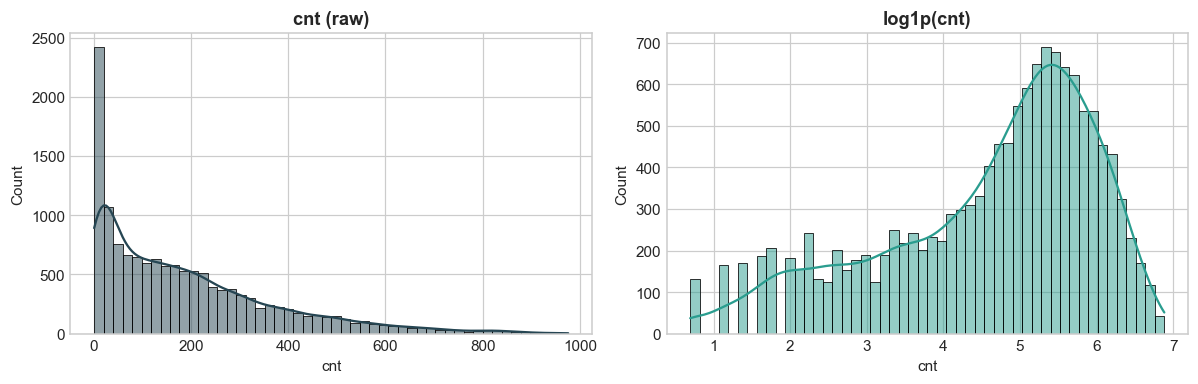

In [4]:
print(y_train.describe().round(2).to_string())
print(f"\nSkewness — raw: {y_train.skew():.2f} | log1p: {np.log1p(y_train).skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(y_train, bins=50, kde=True, color="#264653", ax=axes[0]).set(title="cnt (raw)")
sns.histplot(np.log1p(y_train), bins=50, kde=True, color="#2a9d8f", ax=axes[1]).set(title="log1p(cnt)")
plt.tight_layout(); plt.show()

**Reading:** hourly demand is right-skewed (many quiet hours, a long rush-hour tail). `log1p` reduces skew, but RMSE on the raw scale is the operationally relevant loss (peak-hour stockouts), so the raw target stays primary.

## 3. Shared Pipeline & Evaluation Helpers
Imputation and scaling live inside the `Pipeline`, so they are re-fitted on each training fold only — no leakage.

In [5]:
def make_pipeline(estimator):
    prep = ColumnTransformer([("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                                                 ("scaler", StandardScaler())]),
                               X_train.columns.tolist())])
    return Pipeline([("preprocessor", prep), ("model", estimator)])

SCORING = {"rmse": RMSE, "mae": "neg_mean_absolute_error", "r2": "r2",
           "mape": "neg_mean_absolute_percentage_error"}

In [6]:
cv_folds, test_preds, rows, pipes = {}, {}, {}, {}

def evaluate(name, pipe):
    """5-fold CV on train + fit/predict on the held-out test set."""
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    pred = clone(pipe).fit(X_train, y_train).predict(X_test)
    cv_folds[name], test_preds[name], pipes[name] = -s["test_rmse"], pred, pipe
    rows[name] = {
        "Model": name,
        "CV RMSE": -s["test_rmse"].mean(),  "Test RMSE": root_mean_squared_error(y_test, pred),
        "CV MAE": -s["test_mae"].mean(),    "Test MAE": mean_absolute_error(y_test, pred),
        "CV R²": s["test_r2"].mean(),       "Test R²": r2_score(y_test, pred),
        "CV MAPE (%)": -s["test_mape"].mean() * 100,
        "Test MAPE (%)": mean_absolute_percentage_error(y_test, pred) * 100,
    }
    return pd.Series(rows[name])

## 4. Baseline — Linear Regression
Untuned ordinary least squares: the minimum performance bar every other model must clear.

In [7]:
pd.DataFrame([evaluate("Linear Regression", make_pipeline(LinearRegression()))]).round(3)

,Model,CV RMSE,Test RMSE,CV MAE,Test MAE,CV R²,Test R²,CV MAPE (%),Test MAPE (%)
0,Linear Regression,100.584,97.366,75.053,72.498,0.695,0.701,261.452,261.859


## 5. Hyperparameter Tuning
Two stages per model: **(1)** `RandomizedSearchCV` explores a broad space; **(2)** `GridSearchCV` refines the neighbouring values of the best random configuration (starting from the already-tuned estimator, so parameters not in the grid keep their stage-1 values). Pre-tuning CV RMSE of the default model is recorded for comparison.

In [8]:
tuned = {}

def neighbors(space, best, keys):
    """Grid of each key's best value ± one step in its ordered search space."""
    return {k: space[k][max(space[k].index(best[k]) - 1, 0): space[k].index(best[k]) + 2] for k in keys}

def tune(name, estimator, space, refine_keys, n_iter=10):
    pipe = make_pipeline(estimator)
    pre = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring=RMSE, n_jobs=-1).mean()

    t0 = time.time()
    rnd = RandomizedSearchCV(pipe, space, n_iter=n_iter, cv=cv, scoring=RMSE,
                             random_state=SEED, n_jobs=-1).fit(X_train, y_train)
    grid = GridSearchCV(rnd.best_estimator_, neighbors(space, rnd.best_params_, refine_keys),
                        cv=cv, scoring=RMSE, n_jobs=-1).fit(X_train, y_train)
    elapsed = time.time() - t0

    tuned[name] = dict(pre=pre, post=-grid.best_score_, time=elapsed, space=space,
                       random=rnd, grid=grid, best=grid.best_estimator_)
    print(f"{name}: CV RMSE {pre:.2f} → {-grid.best_score_:.2f} | {elapsed:.0f}s | {grid.best_params_}")

### 5.1 Random Forest (Intermediate 1)

In [9]:
RF_SPACE = {
    "model__n_estimators": [100, 150, 200, 300],
    "model__max_depth": [10, 15, 20, 25, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7, 1.0],
}
tune("Random Forest", RandomForestRegressor(random_state=SEED, n_jobs=1), RF_SPACE,
     ["model__n_estimators", "model__max_depth", "model__min_samples_leaf"])

Random Forest: CV RMSE 43.26 → 42.17 | 90s | {'model__max_depth': 25, 'model__min_samples_leaf': 1, 'model__n_estimators': 150}


### 5.2 Gradient Boosting (Intermediate 2)

In [10]:
GB_SPACE = {
    "model__n_estimators": [150, 250, 350, 500],
    "model__learning_rate": [0.03, 0.05, 0.08, 0.1],
    "model__max_depth": [3, 4, 5, 6],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__min_samples_leaf": [1, 3, 5],
}
tune("Gradient Boosting", GradientBoostingRegressor(random_state=SEED), GB_SPACE,
     ["model__n_estimators", "model__learning_rate", "model__max_depth"])

Gradient Boosting: CV RMSE 62.66 → 39.72 | 140s | {'model__learning_rate': 0.05, 'model__max_depth': 6, 'model__n_estimators': 500}


### 5.3 XGBoost (Advanced)

In [11]:
XGB_SPACE = {
    "model__n_estimators": [300, 500, 700],
    "model__learning_rate": [0.03, 0.05, 0.08, 0.1],
    "model__max_depth": [4, 5, 6, 7],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 0.85, 1.0],
    "model__reg_lambda": [1.0, 2.0, 5.0],
}
tune("XGBoost", XGBRegressor(objective="reg:squarederror", random_state=SEED, n_jobs=1), XGB_SPACE,
     ["model__n_estimators", "model__learning_rate", "model__max_depth"], n_iter=12)

XGBoost: CV RMSE 42.04 → 38.82 | 29s | {'model__learning_rate': 0.05, 'model__max_depth': 7, 'model__n_estimators': 700}


#### Early stopping (XGBoost)
The tuned configuration is re-trained with up to 1000 rounds on an internal 80/20 split of the **training** data (test set untouched); training stops after 30 rounds without validation improvement.

Optimal round: 402 / 1000 (grid-tuned n_estimators: 700) | validation RMSE 38.59


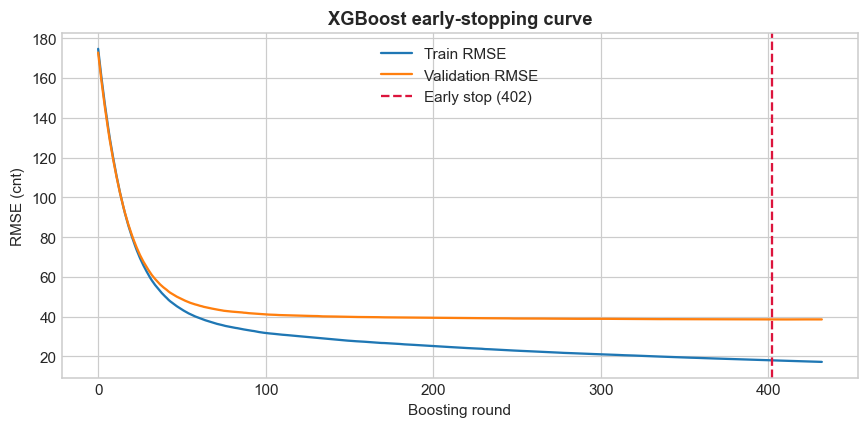

In [12]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=SEED)
prep = clone(tuned["XGBoost"]["best"].named_steps["preprocessor"]).fit(X_fit)

xgb_es = clone(tuned["XGBoost"]["best"].named_steps["model"]).set_params(
    n_estimators=1000, early_stopping_rounds=30, eval_metric="rmse")
xgb_es.fit(prep.transform(X_fit), y_fit,
           eval_set=[(prep.transform(X_fit), y_fit), (prep.transform(X_val), y_val)], verbose=False)

hist = xgb_es.evals_result()
best_it = xgb_es.best_iteration
tuned_n = tuned["XGBoost"]["best"].named_steps["model"].n_estimators
print(f"Optimal round: {best_it} / 1000 (grid-tuned n_estimators: {tuned_n}) | validation RMSE {xgb_es.best_score:.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist["validation_0"]["rmse"], label="Train RMSE")
ax.plot(hist["validation_1"]["rmse"], label="Validation RMSE")
ax.axvline(best_it, color="crimson", ls="--", label=f"Early stop ({best_it})")
ax.set(xlabel="Boosting round", ylabel="RMSE (cnt)", title="XGBoost early-stopping curve")
ax.legend(); plt.tight_layout(); plt.show()

**Reading:** a widening train–validation gap with a flat validation curve marks the point where extra rounds only fit noise. If the early-stopping round is well below the grid-tuned `n_estimators`, the grid value is probably slightly over-built for this learning rate.

## 6. Tuning Diagnostics

In [13]:
tuning_summary = pd.DataFrame([{
    "Model": n,
    "Pre-tuning CV RMSE": t["pre"],
    "Post-tuning CV RMSE": t["post"],
    "Improvement": t["pre"] - t["post"],
    "Improvement (%)": 100 * (t["pre"] - t["post"]) / t["pre"],
    "Tuning time (s)": t["time"],
    "Best parameters": {k.removeprefix("model__"): t["best"].get_params()[k] for k in t["space"]},
} for n, t in tuned.items()])

pd.set_option("display.max_colwidth", None)
display(tuning_summary.round(3))

,Model,Pre-tuning CV RMSE,Post-tuning CV RMSE,Improvement,Improvement (%),Tuning time (s),Best parameters
0,Random Forest,43.257,42.171,1.086,2.510,89.968,"{'n_estimators': 150, 'max_depth': 25, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.7}"
1,Gradient Boosting,62.658,39.719,22.939,36.610,140.166,"{'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 6, 'subsample': 0.7, 'min_samples_leaf': 1}"
2,XGBoost,42.036,38.819,3.217,7.652,28.573,"{'n_estimators': 700, 'learning_rate': 0.05, 'max_depth': 7, 'subsample': 0.7, 'colsample_bytree': 1.0, 'reg_lambda': 1.0}"


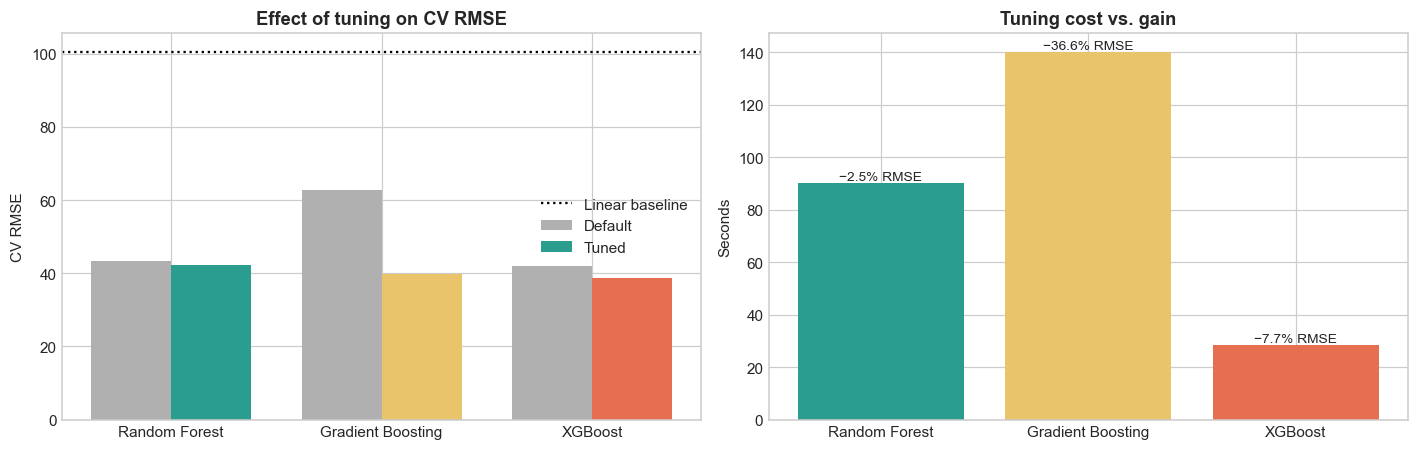

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
names = tuning_summary["Model"]
x, w = np.arange(len(names)), 0.38

axes[0].bar(x - w/2, tuning_summary["Pre-tuning CV RMSE"], w, label="Default", color="#b0b0b0")
axes[0].bar(x + w/2, tuning_summary["Post-tuning CV RMSE"], w, label="Tuned", color=[COLORS[n] for n in names])
axes[0].axhline(rows["Linear Regression"]["CV RMSE"], color="k", ls=":", label="Linear baseline")
axes[0].set(xticks=x, xticklabels=names, ylabel="CV RMSE", title="Effect of tuning on CV RMSE")
axes[0].legend()

bars = axes[1].bar(names, tuning_summary["Tuning time (s)"], color=[COLORS[n] for n in names])
for b, pct in zip(bars, tuning_summary["Improvement (%)"]):
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height(), f"−{pct:.1f}% RMSE", ha="center", va="bottom", fontsize=9)
axes[1].set(ylabel="Seconds", title="Tuning cost vs. gain")
plt.tight_layout(); plt.show()

**Search landscape.** Left: CV RMSE of every random-search trial (sorted) against the default and tuned scores. Right: grid-search RMSE over the two most-varied parameters (minimum over the remaining grid parameters).

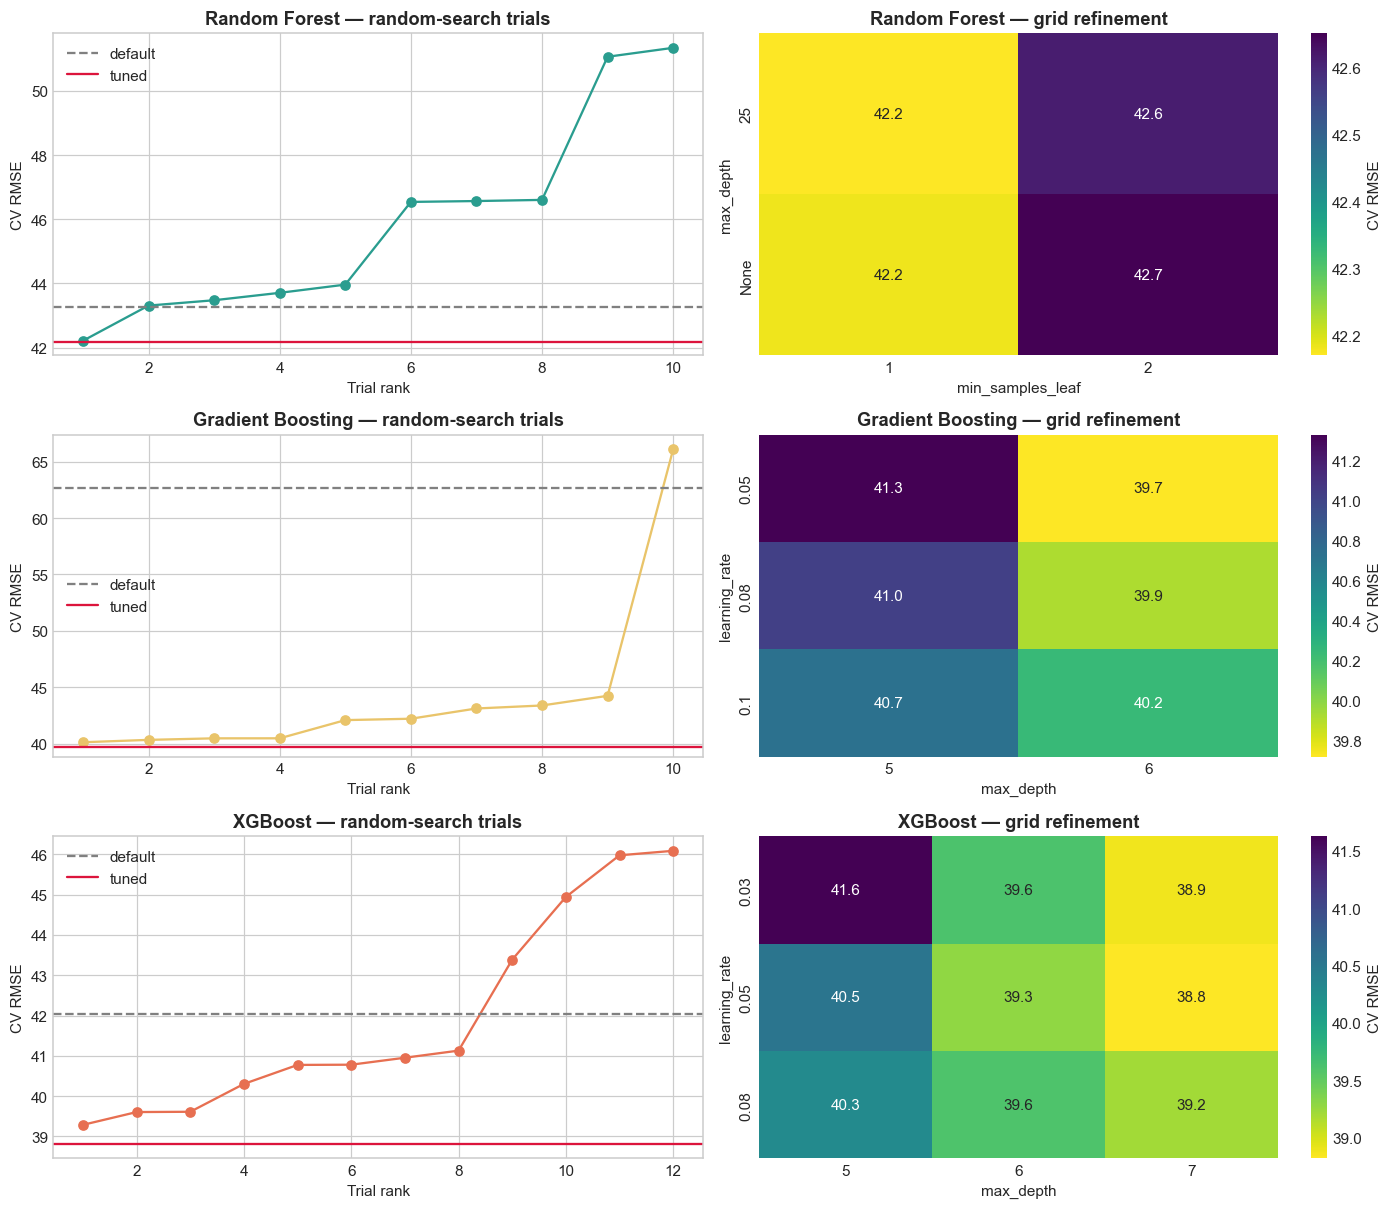

In [15]:
label = lambda v: "None" if v is None else str(v)

fig, axes = plt.subplots(len(tuned), 2, figsize=(13, 3.7 * len(tuned)))
for (name, t), (ax_r, ax_g) in zip(tuned.items(), axes):
    trials = np.sort(-t["random"].cv_results_["mean_test_score"])
    ax_r.plot(range(1, len(trials) + 1), trials, "o-", color=COLORS[name])
    ax_r.axhline(t["pre"], color="grey", ls="--", label="default")
    ax_r.axhline(t["post"], color="crimson", label="tuned")
    ax_r.set(title=f"{name} — random-search trials", xlabel="Trial rank", ylabel="CV RMSE"); ax_r.legend()

    res = pd.DataFrame(t["grid"].cv_results_)
    res["rmse"] = -res["mean_test_score"]
    ps = [c for c in res if c.startswith("param_") and res[c].map(label).nunique() > 1][:2]
    if len(ps) < 2:
        ax_g.axis("off"); continue
    for c in ps: res[c] = res[c].map(label)
    order = lambda c: [label(v) for v in t["grid"].param_grid[c.removeprefix("param_")]]
    piv = res.pivot_table(index=ps[0], columns=ps[1], values="rmse", aggfunc="min")
    piv = piv.reindex(index=order(ps[0]), columns=order(ps[1]))
    sns.heatmap(piv, annot=True, fmt=".1f", cmap="viridis_r", ax=ax_g, cbar_kws={"label": "CV RMSE"})
    ax_g.set(title=f"{name} — grid refinement",
             xlabel=ps[1].removeprefix("param_model__"), ylabel=ps[0].removeprefix("param_model__"))
plt.tight_layout(); plt.show()

**Reading:** boosting models usually gain more from tuning than Random Forest, whose defaults are already near a plateau. A narrow spread across the top random trials, and a smooth (not edge-peaked) grid surface, indicate a stable optimum; a best cell at the grid border would suggest widening the search.

## 7. Model Comparison (5-fold CV & Held-out Test)

In [16]:
for name, t in tuned.items():
    evaluate(name, t["best"])

comparison = pd.DataFrame(rows.values()).sort_values("CV RMSE").reset_index(drop=True)
display(comparison.round(3))

,Model,CV RMSE,Test RMSE,CV MAE,Test MAE,CV R²,Test R²,CV MAPE (%),Test MAPE (%)
0,XGBoost,38.819,37.381,23.558,22.336,0.954,0.956,33.382,32.534
1,Gradient Boosting,39.719,38.021,24.457,23.222,0.952,0.954,37.214,36.065
2,Random Forest,42.171,39.896,25.686,23.959,0.946,0.950,31.520,31.086
3,Linear Regression,100.584,97.366,75.053,72.498,0.695,0.701,261.452,261.859


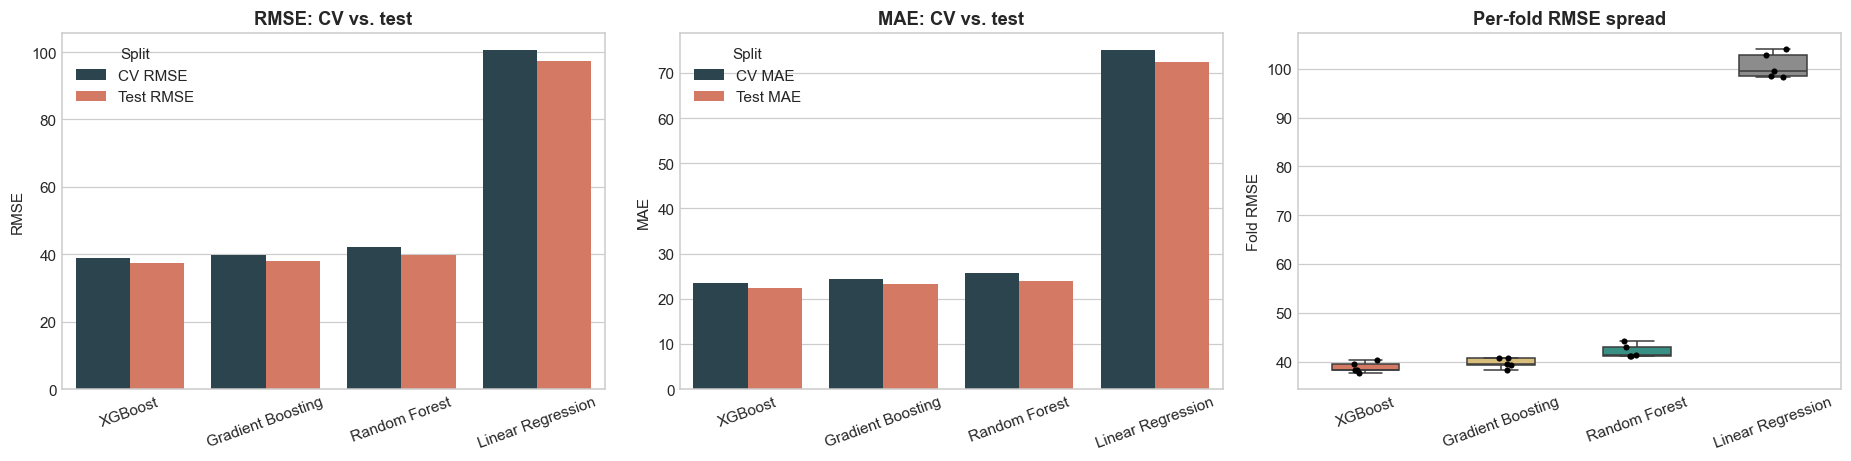

In [17]:
order = comparison["Model"].tolist()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))

for ax, m in zip(axes[:2], ["RMSE", "MAE"]):
    long = comparison.melt(id_vars="Model", value_vars=[f"CV {m}", f"Test {m}"], var_name="Split", value_name=m)
    sns.barplot(data=long, x="Model", y=m, hue="Split", order=order, palette=["#264653", "#e76f51"], ax=ax)
    ax.set_title(f"{m}: CV vs. test"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)

folds = pd.DataFrame(cv_folds)[order].melt(var_name="Model", value_name="Fold RMSE")
sns.boxplot(data=folds, x="Model", y="Fold RMSE", order=order, palette=COLORS, ax=axes[2], width=0.5)
sns.stripplot(data=folds, x="Model", y="Fold RMSE", order=order, color="k", size=4, ax=axes[2])
axes[2].set_title("Per-fold RMSE spread"); axes[2].set_xlabel(""); axes[2].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

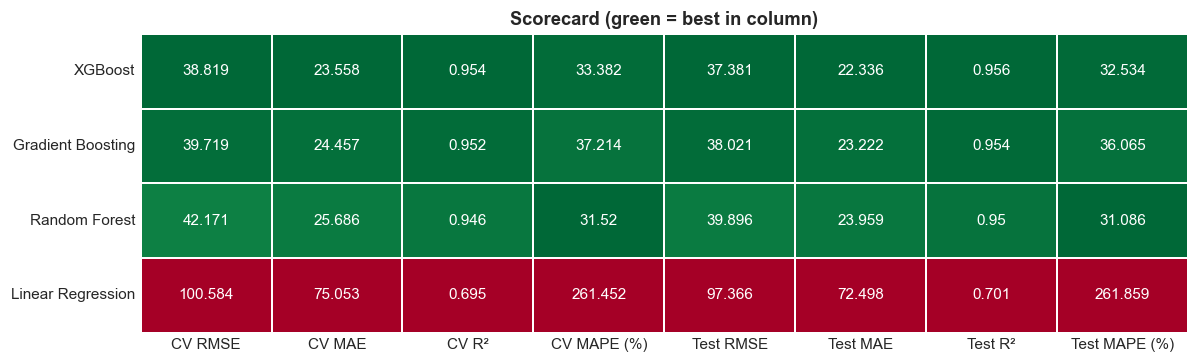

In [18]:
metrics = ["RMSE", "MAE", "R²", "MAPE (%)"]
cols = [f"{s} {m}" for s in ("CV", "Test") for m in metrics]
score = comparison.set_index("Model")[cols]

norm = (score - score.min()) / (score.max() - score.min())          # 0 = best-in-column ...
r2_cols = [c for c in cols if "R²" in c]
norm[r2_cols] = 1 - norm[r2_cols]                                    # ... flipped for R² (higher = better)

plt.figure(figsize=(11, 3.4))
sns.heatmap(norm, annot=score.round(3).to_numpy(), fmt="", cmap="RdYlGn_r", cbar=False, linewidths=1)
plt.title("Scorecard (green = best in column)"); plt.ylabel(""); plt.tight_layout(); plt.show()

**Target transformation check.** The best CV model is refitted on `log1p(cnt)` and predictions are inverse-transformed (`expm1`) before scoring on the original scale.

In [19]:
best_name = comparison.loc[0, "Model"]
best_pipe = clone(pipes[best_name]).fit(X_train, y_train)
best_pred = test_preds[best_name]

log_pred = np.expm1(clone(pipes[best_name]).fit(X_train, np.log1p(y_train)).predict(X_test)).clip(0)
target_check = pd.DataFrame({
    "Target": ["raw cnt", "log1p(cnt)"],
    "Test RMSE": [root_mean_squared_error(y_test, p) for p in (best_pred, log_pred)],
    "Test MAE": [mean_absolute_error(y_test, p) for p in (best_pred, log_pred)],
    "Test MAPE (%)": [100 * mean_absolute_percentage_error(y_test, p) for p in (best_pred, log_pred)],
}).round(3)
print(f"Best model (lowest CV RMSE): {best_name}")
display(target_check)

Best model (lowest CV RMSE): XGBoost


,Target,Test RMSE,Test MAE,Test MAPE (%)
0,raw cnt,37.381,22.336,32.534
1,log1p(cnt),37.869,22.102,23.091


**Reading:**
- **Linear → ensembles:** a large error reduction means demand is driven by interactions (hour × working day × temperature) that a linear hyperplane cannot express.
- **Generalisation:** CV and test errors of similar size mean little overfitting to the folds.
- **Log target:** it typically helps relative error on low-count night hours (MAPE) but hurts RMSE, since it down-weights peaks. Priority is avoiding peak-hour stockouts, so the raw-target model is kept.
- **Caveat:** shuffled K-fold lets adjacent hours of the same day fall in train and validation folds, which can make CV optimistic for time-ordered data. A chronological split (`TimeSeriesSplit`) is the stricter check before deployment.

## 8. Residual Diagnostics
`residual = actual − predicted` for the best model on the test set.

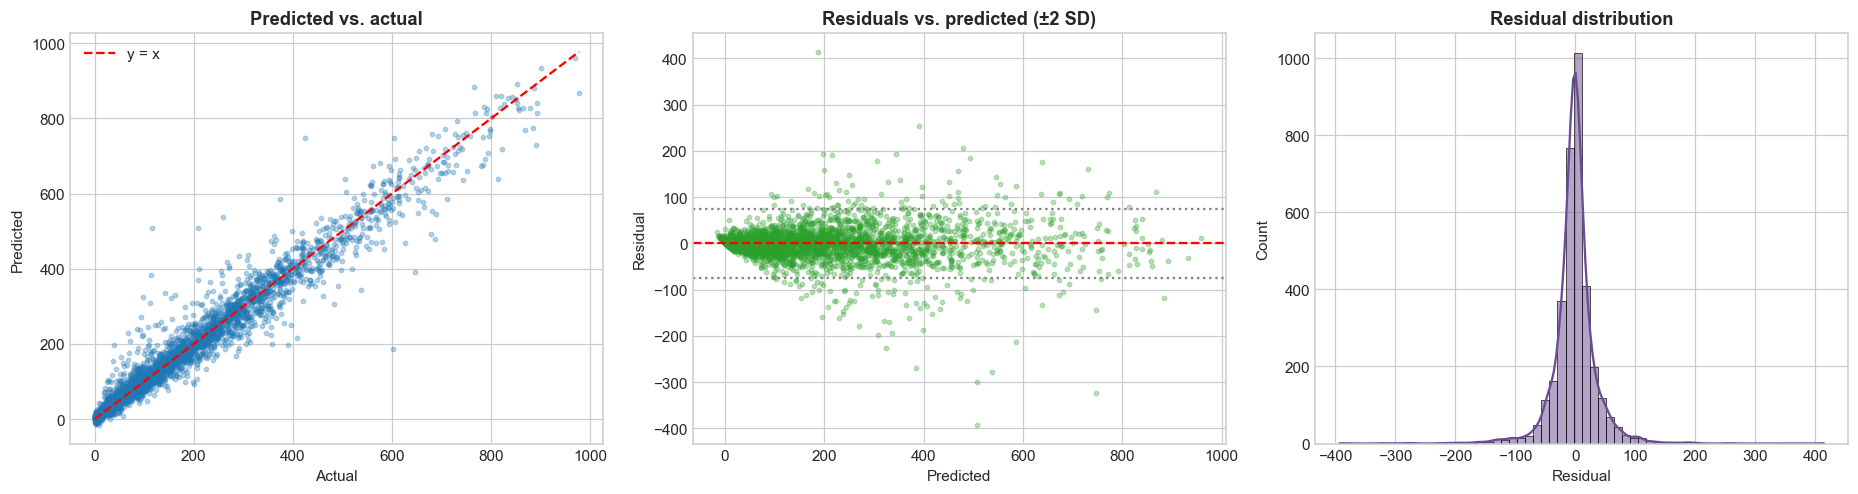

Mean -0.89 | SD 37.37 | under-predicted >100: 44 h | over-predicted >100: 59 h


In [20]:
res = y_test.to_numpy() - best_pred
abs_err = np.abs(res)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].scatter(y_test, best_pred, s=8, alpha=0.3, color="#1f77b4")
lim = [0, max(y_test.max(), best_pred.max())]
ax[0].plot(lim, lim, "r--", label="y = x"); ax[0].legend()
ax[0].set(xlabel="Actual", ylabel="Predicted", title="Predicted vs. actual")

ax[1].scatter(best_pred, res, s=8, alpha=0.3, color="#2ca02c")
ax[1].axhline(0, color="r", ls="--")
for s in (-2, 2): ax[1].axhline(s * res.std(), color="grey", ls=":")
ax[1].set(xlabel="Predicted", ylabel="Residual", title="Residuals vs. predicted (±2 SD)")

sns.histplot(res, bins=60, kde=True, color="#6a4c93", ax=ax[2]).set(title="Residual distribution", xlabel="Residual")
plt.tight_layout(); plt.show()

print(f"Mean {res.mean():.2f} | SD {res.std():.2f} | under-predicted >100: {(res > 100).sum()} h | over-predicted >100: {(res < -100).sum()} h")

**Error by demand level** (and by hour of day when `hr` is available) — quantifies the heteroscedasticity visible above.

,MAE,RMSE,Bias
Predicted-demand quintile,,,
Q1 (low),5.56,7.80,0.56
Q2,13.84,18.71,-1.46
Q3,20.51,28.51,-1.16
Q4,31.16,46.56,0.93
Q5 (high),40.63,59.98,-3.30


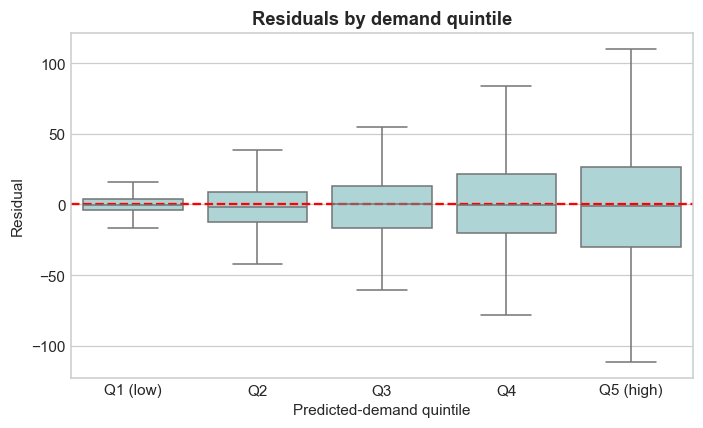

,actual,pred,res
1820,601,186.899994,414.1
3455,116,508.299988,-392.3
1928,425,747.299988,-322.3
2583,208,507.600006,-299.6
1157,259,537.500000,-278.5


In [21]:
diag = pd.DataFrame({"actual": y_test.to_numpy(), "pred": best_pred, "res": res, "abs_err": abs_err})
diag["Predicted-demand quintile"] = pd.qcut(diag["pred"].rank(method="first"), 5,
                                            labels=["Q1 (low)", "Q2", "Q3", "Q4", "Q5 (high)"])

by_q = diag.groupby("Predicted-demand quintile", observed=True).agg(
    MAE=("abs_err", "mean"), RMSE=("res", lambda r: np.sqrt((r**2).mean())), Bias=("res", "mean"))
display(by_q.round(2))

has_hr = "hr" in X_test and X_test["hr"].between(0, 23).all()
fig, axes = plt.subplots(1, 2 if has_hr else 1, figsize=(13 if has_hr else 6.5, 4), squeeze=False)
sns.boxplot(data=diag, x="Predicted-demand quintile", y="res", color="#a8dadc", showfliers=False, ax=axes[0, 0])
axes[0, 0].axhline(0, color="r", ls="--"); axes[0, 0].set(title="Residuals by demand quintile", ylabel="Residual")
if has_hr:
    diag.assign(hr=X_test["hr"].to_numpy()).groupby("hr")["abs_err"].mean().plot.bar(ax=axes[0, 1], color="#e76f51")
    axes[0, 1].set(title="Mean absolute error by hour", xlabel="Hour", ylabel="MAE")
plt.tight_layout(); plt.show()

display(diag.sort_values("abs_err", ascending=False).head(5)[["actual", "pred", "res"]].round(1))

**Reading:**
- **Unbiased but heteroscedastic:** residuals centre near zero, yet spread grows with predicted demand — absolute errors are small overnight and largest in the top quintile (rush hours), as expected for count data.
- **Under-prediction (`res > 0`)** typically reflects unmodelled demand surges (events, unusually good weather); **over-prediction (`res < 0`)** reflects suppressed ridership (sudden rain, transit disruption, unrecorded holidays). Neither is visible in calendar/weather features.

## 9. Permutation Importance
Increase in test RMSE when one feature is shuffled (10 repeats). Correlated pairs (e.g. `temp`/`atemp`) split their importance, so read them jointly.

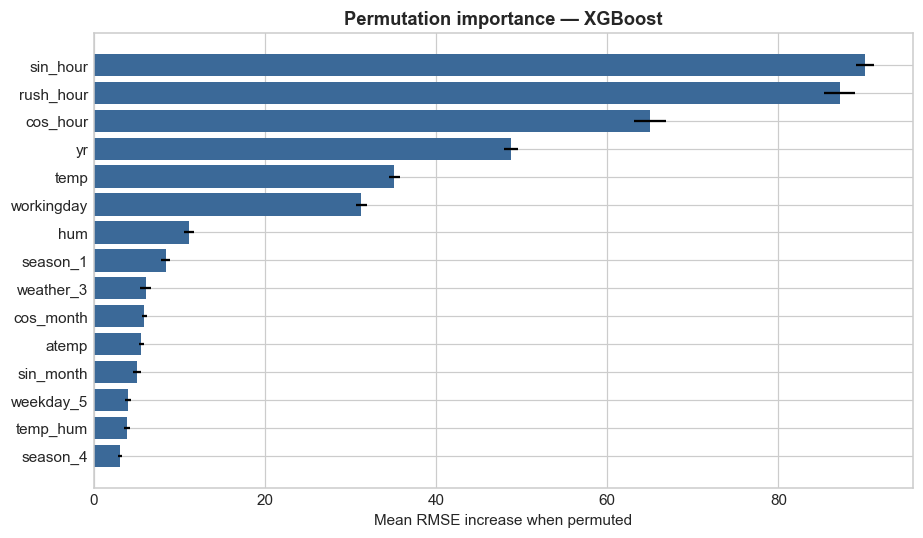

In [22]:
perm = permutation_importance(best_pipe, X_test, y_test, n_repeats=10, scoring=RMSE,
                              random_state=SEED, n_jobs=-1)
perm_df = (pd.DataFrame({"Feature": X_test.columns, "Importance": perm.importances_mean, "Std": perm.importances_std})
           .sort_values("Importance", ascending=False).reset_index(drop=True))

top = perm_df.head(15).iloc[::-1]
plt.figure(figsize=(8.5, 5))
plt.barh(top["Feature"], top["Importance"], xerr=top["Std"], color="#3b6998")
plt.xlabel("Mean RMSE increase when permuted"); plt.title(f"Permutation importance — {best_name}")
plt.tight_layout(); plt.show()

## 10. SHAP Interpretability
`TreeExplainer` on the fitted best model. SHAP values are computed on the scaled inputs the model sees, while plots display **original feature values** for readability (scaling is monotonic, so colours and dependence shapes are unchanged).

In [23]:
prep, model = best_pipe.named_steps["preprocessor"], best_pipe.named_steps["model"]
feat = [n.split("__")[-1] for n in prep.get_feature_names_out()]
X_test_t = pd.DataFrame(prep.transform(X_test), columns=feat, index=X_test.index)

explainer = shap.TreeExplainer(model)
shap_vals = explainer.shap_values(X_test_t)
base = float(np.ravel(explainer.expected_value)[0])

sv = shap.Explanation(values=shap_vals, base_values=np.full(len(X_test), base),
                      data=X_test.to_numpy(), feature_names=feat)

additivity = np.abs(shap_vals.sum(axis=1) + base - best_pred).max()
print(f"Base value E[f(x)] = {base:.1f} bikes/h | max additivity error = {additivity:.2e}")

Base value E[f(x)] = 190.5 bikes/h | max additivity error = 1.83e-03


### 10.1 Global importance

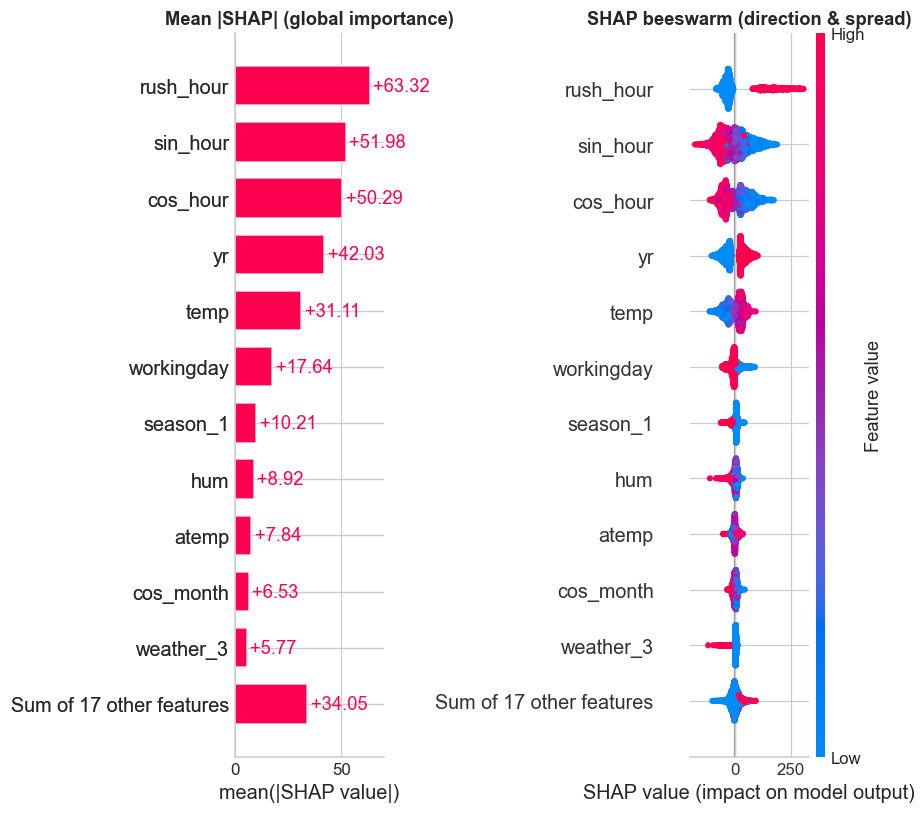

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6))
plt.sca(axes[0]); shap.plots.bar(sv, max_display=12, show=False); axes[0].set_title("Mean |SHAP| (global importance)")
plt.sca(axes[1]); shap.plots.beeswarm(sv, max_display=12, show=False, plot_size=None); axes[1].set_title("SHAP beeswarm (direction & spread)")
plt.tight_layout(); plt.show()

**Reading:**
- **Time-of-day features** are expected to dominate: commute-hour values push predictions far above the base rate, overnight hours far below.
- **Temperature** acts monotonically up to a comfort range; **`yr`** adds a near-constant uplift (system growth between 2011 and 2012); **`workingday`** reshapes the daily profile (bimodal commute peaks vs. midday leisure).
- Wide, bimodal beeswarm rows signal strong interactions rather than a single additive effect.

### 10.2 Dependence plots (top 3 features)
Each point is one test hour; colour shows the feature SHAP identifies as the strongest interaction partner.

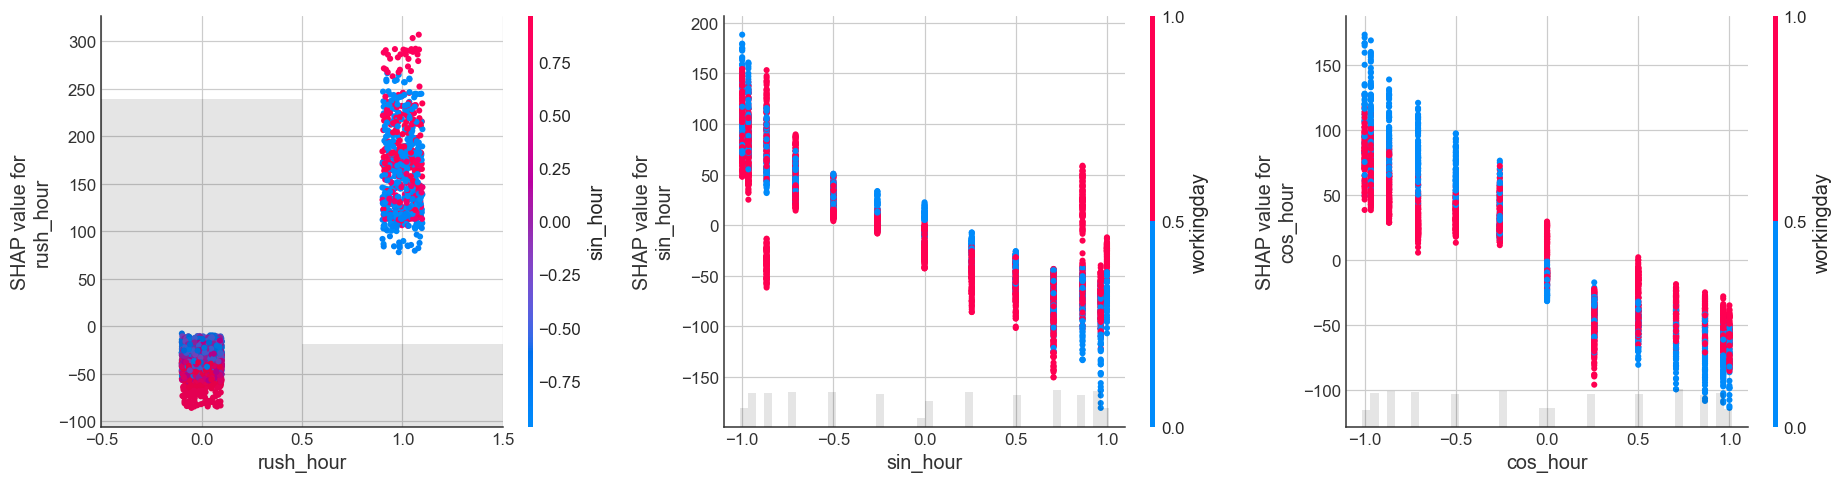

In [25]:
top3 = [feat[i] for i in np.argsort(-np.abs(shap_vals).mean(axis=0))[:3]]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, f in zip(axes, top3):
    shap.plots.scatter(sv[:, f], color=sv, ax=ax, show=False)
plt.tight_layout(); plt.show()

### 10.3 Interaction effects
Mean absolute SHAP interaction values on a 500-hour sample (off-diagonal = pairwise interaction; diagonal = main effect).

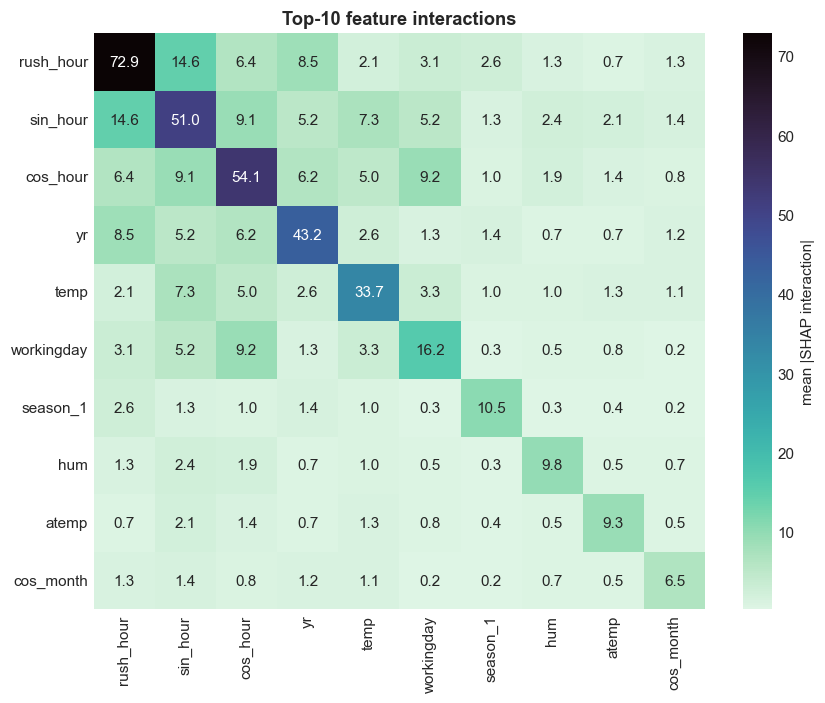

In [26]:
try:
    sample = X_test_t.sample(min(500, len(X_test_t)), random_state=SEED)
    inter = np.abs(explainer.shap_interaction_values(sample)).mean(axis=0)
    idx = np.argsort(-np.abs(shap_vals).mean(axis=0))[:10]
    plt.figure(figsize=(8, 6.5))
    sns.heatmap(pd.DataFrame(inter[np.ix_(idx, idx)], index=np.array(feat)[idx], columns=np.array(feat)[idx]),
                cmap="mako_r", annot=True, fmt=".1f", cbar_kws={"label": "mean |SHAP interaction|"})
    plt.title("Top-10 feature interactions"); plt.tight_layout(); plt.show()
except Exception as e:
    print(f"Interaction values unavailable for {type(model).__name__}: {e}")

### 10.4 SHAP vs. permutation importance

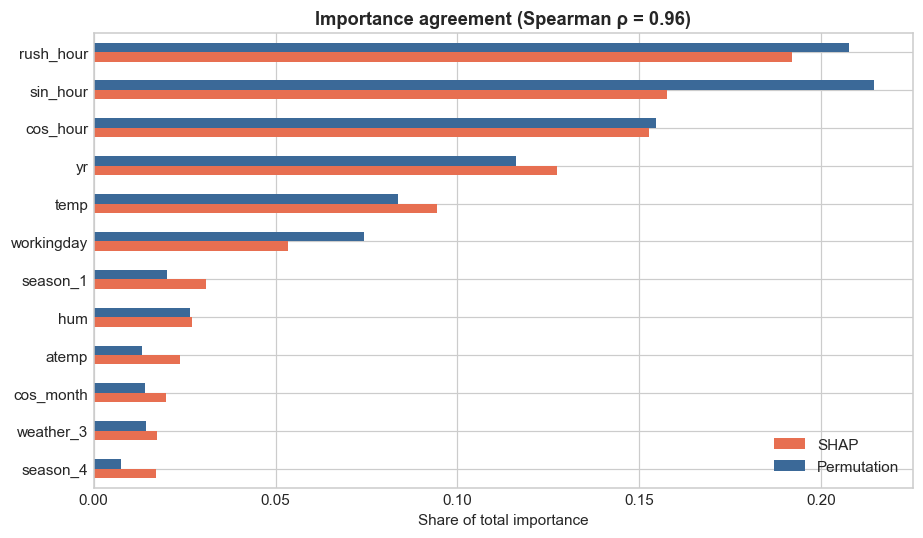

In [27]:
cmp = pd.DataFrame({"SHAP": np.abs(shap_vals).mean(axis=0),
                    "Permutation": perm_df.set_index("Feature")["Importance"].reindex(feat).clip(lower=0).to_numpy()},
                   index=feat)
cmp = cmp / cmp.sum()
rho = cmp.corr(method="spearman").loc["SHAP", "Permutation"]

cmp.sort_values("SHAP", ascending=False).head(12).iloc[::-1].plot.barh(figsize=(8.5, 5), color=["#e76f51", "#3b6998"])
plt.xlabel("Share of total importance"); plt.title(f"Importance agreement (Spearman ρ = {rho:.2f})")
plt.tight_layout(); plt.show()

**Reading:** a high rank correlation means both methods agree on what drives the model. Disagreements usually involve correlated features, where permutation importance is diluted but SHAP still credits each feature's contribution.

### 10.5 Local explanations

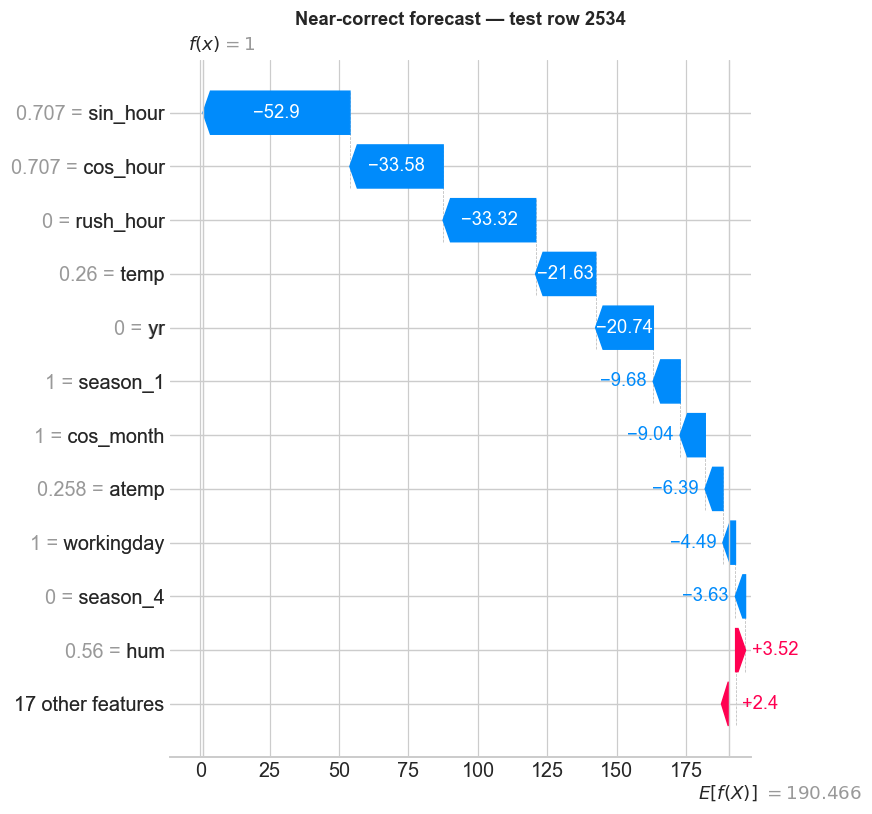

Actual 1 | Predicted 1.0 | Abs. error 0.0


In [28]:
def explain_row(i, title):
    shap.plots.waterfall(sv[i], max_display=12, show=False)
    plt.title(f"{title} — test row {i}", fontsize=12)
    plt.tight_layout(); plt.show()
    print(f"Actual {y_test.iloc[i]:.0f} | Predicted {best_pred[i]:.1f} | Abs. error {abs_err[i]:.1f}")

i_good, i_bad = int(np.argmin(abs_err)), int(np.argmax(abs_err))
explain_row(i_good, "Near-correct forecast")

**Near-correct:** all major contributors (time of day, working-day status, year, weather) point the same way for a routine hour, so the additive decomposition lands almost exactly on the observed count.

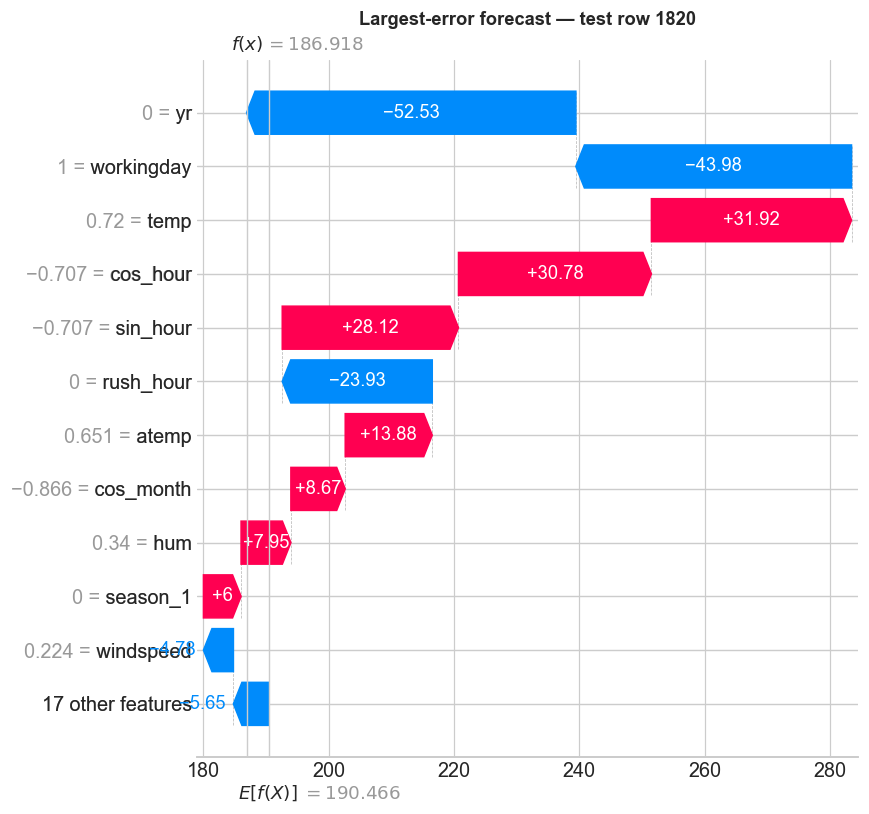

Actual 601 | Predicted 186.9 | Abs. error 414.1


In [29]:
explain_row(i_bad, "Largest-error forecast")

**Largest error:** the explanation is internally consistent — the model confidently applies the usual hour/weather/year effects — yet reality departs from them. That points to an exogenous shock absent from the features (event, mid-hour storm, transit outage, atypical holiday), i.e. an information limit rather than a fitting failure.

**Why do the worst misses happen?** Decision plot of the 15 largest-error test hours: each line is one hour's path from the base value to its prediction.

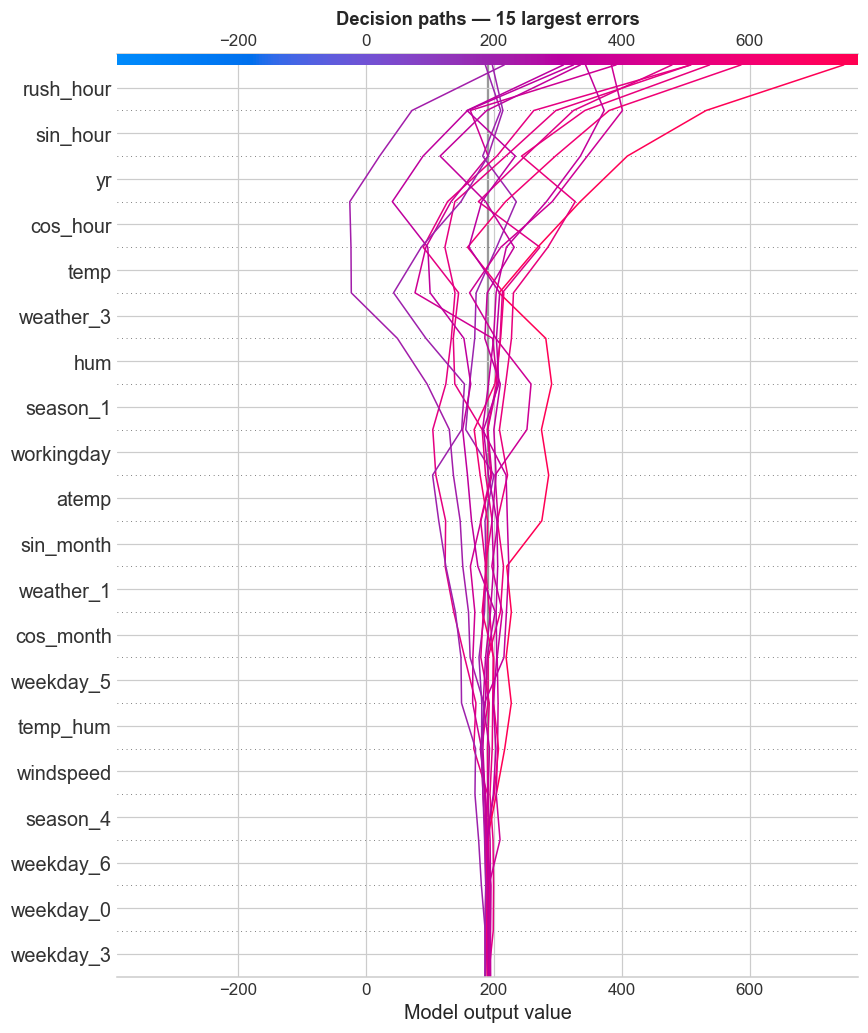

In [30]:
worst = np.argsort(-abs_err)[:15]
shap.decision_plot(base, shap_vals[worst], feature_names=feat, show=False)
plt.title("Decision paths — 15 largest errors"); plt.tight_layout(); plt.show()

**Reading:** if these paths share the same dominant drivers (typically peak-hour temporal features), the failures are concentrated in rush-hour regimes — consistent with the heteroscedasticity in §8 and a sign that event or incident features would add the most value.

## 11. Takeaways & Export

In [31]:
b = comparison.iloc[0]
lin = comparison.set_index("Model").loc["Linear Regression"]

print(f"Best model (CV RMSE): {b['Model']}")
print(f"  Test RMSE {b['Test RMSE']:.1f} | MAE {b['Test MAE']:.1f} | R² {b['Test R²']:.3f} | MAPE {b['Test MAPE (%)']:.1f}%")
print(f"  vs. Linear baseline: RMSE {100 * (1 - b['Test RMSE'] / lin['Test RMSE']):.1f}% lower, R² {lin['Test R²']:.3f} → {b['Test R²']:.3f}")
print(f"  CV–test RMSE gap: {b['Test RMSE'] - b['CV RMSE']:+.2f}")
print(f"  Top SHAP features:        {top3}")
print(f"  Top permutation features: {perm_df['Feature'].head(3).tolist()}")

Best model (CV RMSE): XGBoost
  Test RMSE 37.4 | MAE 22.3 | R² 0.956 | MAPE 32.5%
  vs. Linear baseline: RMSE 61.6% lower, R² 0.701 → 0.956
  CV–test RMSE gap: -1.44
  Top SHAP features:        ['rush_hour', 'sin_hour', 'cos_hour']
  Top permutation features: ['sin_hour', 'rush_hour', 'cos_hour']


In [32]:
joblib.dump(best_pipe, REPORTS / "best_bike_demand_model.joblib")
comparison.to_csv(REPORTS / "model_comparison.csv", index=False)
tuning_summary.to_csv(REPORTS / "tuning_summary.csv", index=False)
print("Saved to", REPORTS.resolve(), "→", sorted(p.name for p in REPORTS.iterdir()))

Saved to C:\KBTU\1. MSc\1st semester\ML\PROJECT\reports → ['best_bike_demand_model.joblib', 'feature_engineering_summary.csv', 'feature_importance.csv', 'figures', 'model_comparison.csv', 'original_vs_engineered.csv', 'proposal_comparison.csv', 'tuning_summary.csv']


## 12. Check Our Proposal Question

**Proposal:** *Does transforming temporal features into cyclical sine/cosine representations achieve lower RMSE than ordinal integer encoding across gradient-boosted regression pipelines?*

This section compares the **engineered dataset** (cyclic `mnth`/`hr` sine-cosine features) against the **original feature set** (ordinal integer `mnth`/`hr`). The Random Forest, Gradient Boosting, and XGBoost models use the tuned hyperparameters reported by this notebook; Linear Regression is included as the baseline.


In [ ]:
X_original_train = pd.read_csv(DATA / "X_original_train.csv")
X_original_test = pd.read_csv(DATA / "X_original_test.csv")

print(f"Ordinal split ? train {X_original_train.shape} | test {X_original_test.shape}")
print(f"Ordinal temporal features: mnth=1-12, hr=0-23")


def make_original_pipeline(estimator):
    prep = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), X_original_train.columns.tolist())
    ])
    return Pipeline([("preprocessor", prep), ("model", estimator)])

ordinal_models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=150, max_depth=25, min_samples_split=2,
        min_samples_leaf=1, max_features=0.7, random_state=SEED, n_jobs=1),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=6,
        subsample=0.7, min_samples_leaf=1, random_state=SEED),
    "XGBoost": XGBRegressor(
        n_estimators=700, learning_rate=0.05, max_depth=7, subsample=0.7,
        colsample_bytree=1.0, reg_lambda=1.0, objective="reg:squarederror",
        random_state=SEED, n_jobs=1),
    "Linear Regression": LinearRegression(),
}

ordinal_rows = []
ordinal_preds = {}
ordinal_cv = {}
for name, estimator in ordinal_models.items():
    pipe = make_original_pipeline(estimator)
    scores = cross_validate(pipe, X_original_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    pred = clone(pipe).fit(X_original_train, y_train).predict(X_original_test)
    ordinal_cv[name] = -scores["test_rmse"]
    ordinal_preds[name] = pred
    ordinal_rows.append({
        "Model": name,
        "CV RMSE": -scores["test_rmse"].mean(),
        "Test RMSE": root_mean_squared_error(y_test, pred),
        "CV MAE": -scores["test_mae"].mean(),
        "Test MAE": mean_absolute_error(y_test, pred),
        "CV R2": scores["test_r2"].mean(),
        "Test R2": r2_score(y_test, pred),
    })

ordinal_comparison = pd.DataFrame(ordinal_rows)
engineered_comparison = pd.read_csv(REPORTS / "model_comparison.csv")

proposal_comparison = pd.concat([
    engineered_comparison.assign(Representation="Cyclical / engineered"),
    ordinal_comparison.assign(Representation="Ordinal integers")
], ignore_index=True)
proposal_comparison = proposal_comparison.sort_values(
    ["Model", "CV RMSE"], ascending=[True, True]).reset_index(drop=True)
proposal_comparison.to_csv(REPORTS / "proposal_comparison.csv", index=False)

display(proposal_comparison[["Representation", "Model", "CV RMSE", "Test RMSE", "CV R2", "Test R2"]].round(3))

proposal_pivot = proposal_comparison.pivot(index="Model", columns="Representation", values="Test RMSE")
proposal_pivot["RMSE change (ordinal - cyclical)"] = proposal_pivot["Ordinal integers"] - proposal_pivot["Cyclical / engineered"]
proposal_pivot["Cyclical lower RMSE?"] = proposal_pivot["RMSE change (ordinal - cyclical)"] > 0
display(proposal_pivot.round(3))


Ordinal split ? train (13903, 12) | test (3476, 12)
Ordinal temporal features: mnth=1-12, hr=0-23


,Representation,Model,CV RMSE,Test RMSE,CV R?,Test R?
0,Cyclical / engineered,Gradient Boosting,39.719,38.021,NaN,NaN
1,Ordinal integers,Gradient Boosting,40.158,38.560,0.951,0.953
2,Cyclical / engineered,Linear Regression,100.584,97.366,NaN,NaN
3,Ordinal integers,Linear Regression,142.564,139.211,0.387,0.388
4,Cyclical / engineered,Random Forest,42.171,39.896,NaN,NaN
5,Ordinal integers,Random Forest,43.008,40.689,0.944,0.948
6,Cyclical / engineered,XGBoost,38.819,37.381,NaN,NaN
7,Ordinal integers,XGBoost,39.099,37.313,0.954,0.956


Representation,Cyclical / engineered,Ordinal integers,RMSE change (ordinal - cyclical),Cyclical lower RMSE?
Model,,,,
Gradient Boosting,38.021,38.560,0.539,True
Linear Regression,97.366,139.211,41.845,True
Random Forest,39.896,40.689,0.793,True
XGBoost,37.381,37.313,-0.068,False


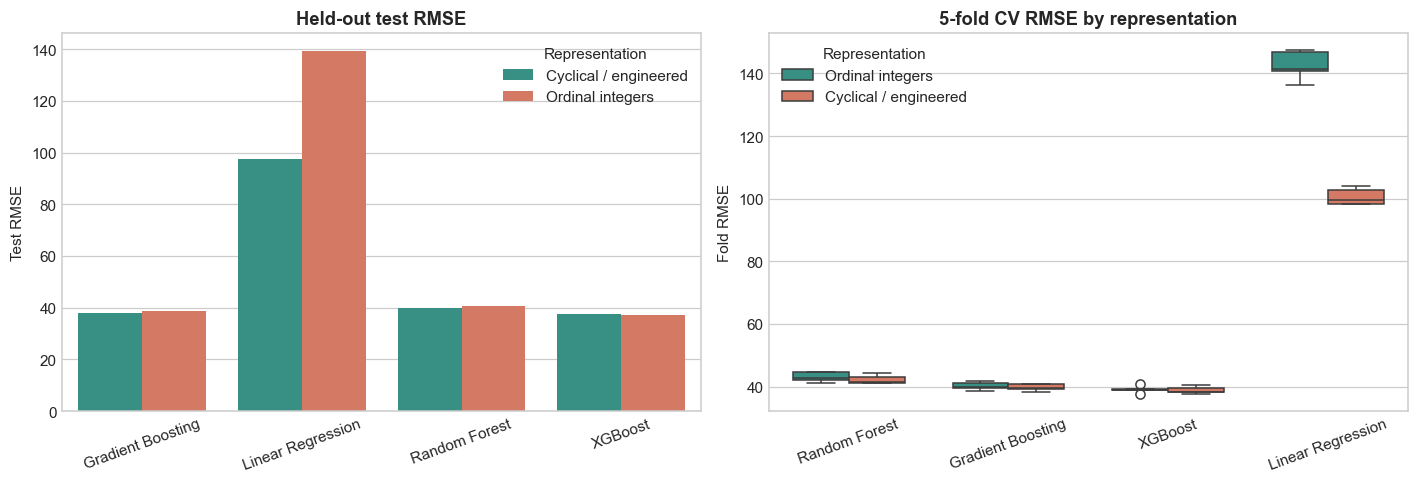

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

proposal_plot = proposal_comparison.sort_values(["Model", "Representation"])
sns.barplot(data=proposal_plot, x="Model", y="Test RMSE", hue="Representation", palette=["#2a9d8f", "#e76f51"], ax=axes[0])
axes[0].set_title("Held-out test RMSE")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)

fold_rows = []
for name, folds in ordinal_cv.items():
    for value in folds:
        fold_rows.append({"Model": name, "Representation": "Ordinal integers", "Fold RMSE": value})
for name, folds in cv_folds.items():
    for value in folds:
        fold_rows.append({"Model": name, "Representation": "Cyclical / engineered", "Fold RMSE": value})
proposal_folds = pd.DataFrame(fold_rows)
sns.boxplot(data=proposal_folds, x="Model", y="Fold RMSE", hue="Representation", palette=["#2a9d8f", "#e76f51"], width=0.7, ax=axes[1])
axes[1].set_title("5-fold CV RMSE by representation")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()


### 12.2 Additional proposal visualizations

These views separate CV evidence from held-out evidence and show whether improvements are consistent or concentrated in a single model.


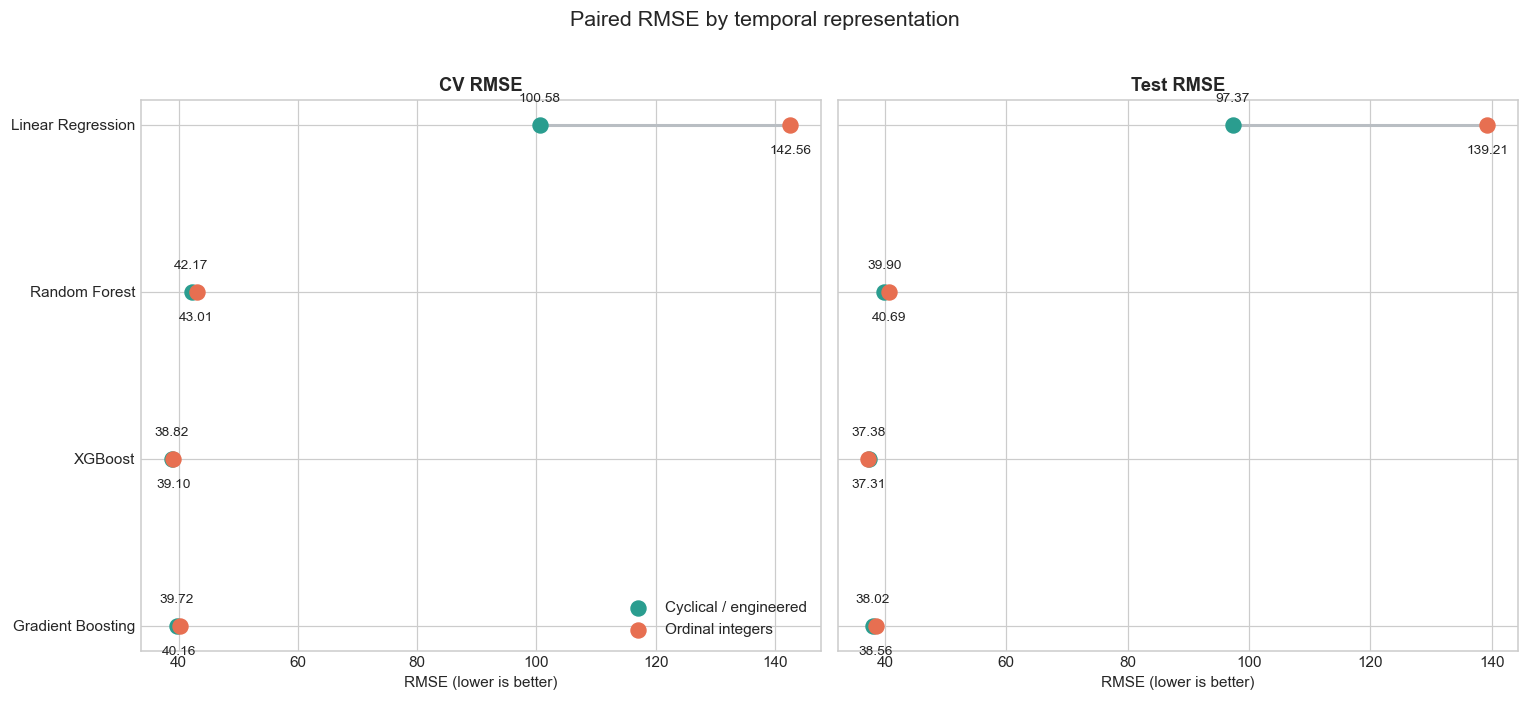

In [35]:
# Paired comparison of CV and test RMSE
proposal_pair = proposal_comparison.pivot(index="Model", columns="Representation", values=["CV RMSE", "Test RMSE"])
model_order = ["Gradient Boosting", "XGBoost", "Random Forest", "Linear Regression"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), sharey=True)
for ax, metric in zip(axes, ["CV RMSE", "Test RMSE"]):
    for y, model in enumerate(model_order):
        values = proposal_pair.loc[model, metric]
        cyclical = values["Cyclical / engineered"]
        ordinal = values["Ordinal integers"]
        ax.plot([cyclical, ordinal], [y, y], color="#b9bec3", lw=2, zorder=1)
        ax.scatter(cyclical, y, s=95, color="#2a9d8f", label="Cyclical / engineered" if y == 0 else None, zorder=3)
        ax.scatter(ordinal, y, s=95, color="#e76f51", label="Ordinal integers" if y == 0 else None, zorder=3)
        ax.text(cyclical, y + 0.12, f"{cyclical:.2f}", ha="center", va="bottom", fontsize=9)
        ax.text(ordinal, y - 0.12, f"{ordinal:.2f}", ha="center", va="top", fontsize=9)
    ax.set_yticks(range(len(model_order)))
    ax.set_yticklabels(model_order)
    ax.set_xlabel("RMSE (lower is better)")
    ax.set_title(metric)
    ax.invert_yaxis()
axes[0].legend(loc="lower right", frameon=False)
plt.suptitle("Paired RMSE by temporal representation", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


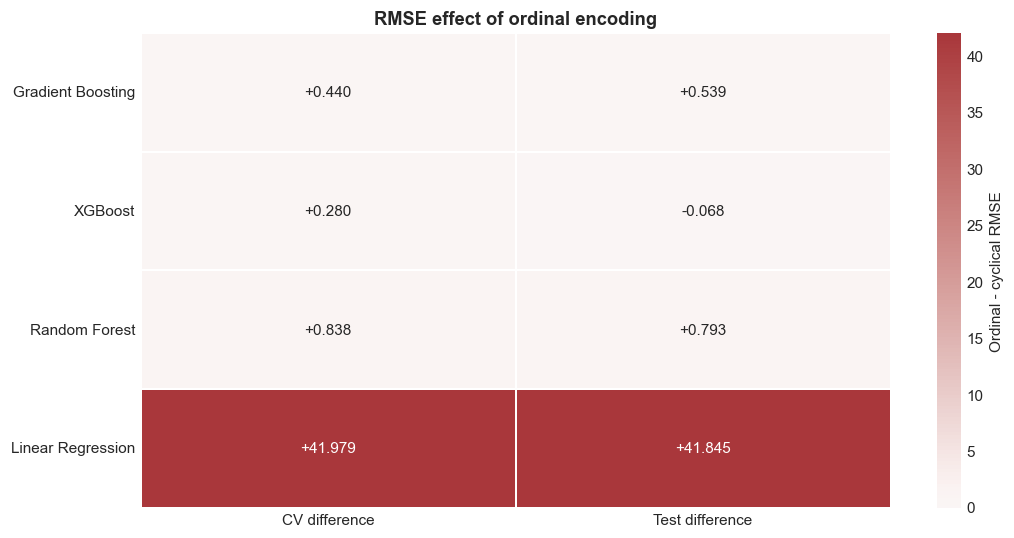

Positive value = ordinal encoding has higher RMSE; negative value = ordinal encoding is better.


In [36]:
# RMSE difference for each model: ordinal RMSE minus cyclical RMSE
proposal_diff = proposal_comparison.pivot(index="Model", columns="Representation")
difference_rows = []
for model in model_order:
    cyc_cv = proposal_diff.loc[model, ("CV RMSE", "Cyclical / engineered")]
    ord_cv = proposal_diff.loc[model, ("CV RMSE", "Ordinal integers")]
    cyc_test = proposal_diff.loc[model, ("Test RMSE", "Cyclical / engineered")]
    ord_test = proposal_diff.loc[model, ("Test RMSE", "Ordinal integers")]
    difference_rows.append({
        "Model": model,
        "CV difference": ord_cv - cyc_cv,
        "Test difference": ord_test - cyc_test,
    })
rmse_difference = pd.DataFrame(difference_rows).set_index("Model")

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(rmse_difference, annot=True, fmt="+.3f", cmap="vlag", center=0,
            linewidths=1, linecolor="white", cbar_kws={"label": "Ordinal - cyclical RMSE"}, ax=ax)
ax.set_title("RMSE effect of ordinal encoding")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

print("Positive value = ordinal encoding has higher RMSE; negative value = ordinal encoding is better.")


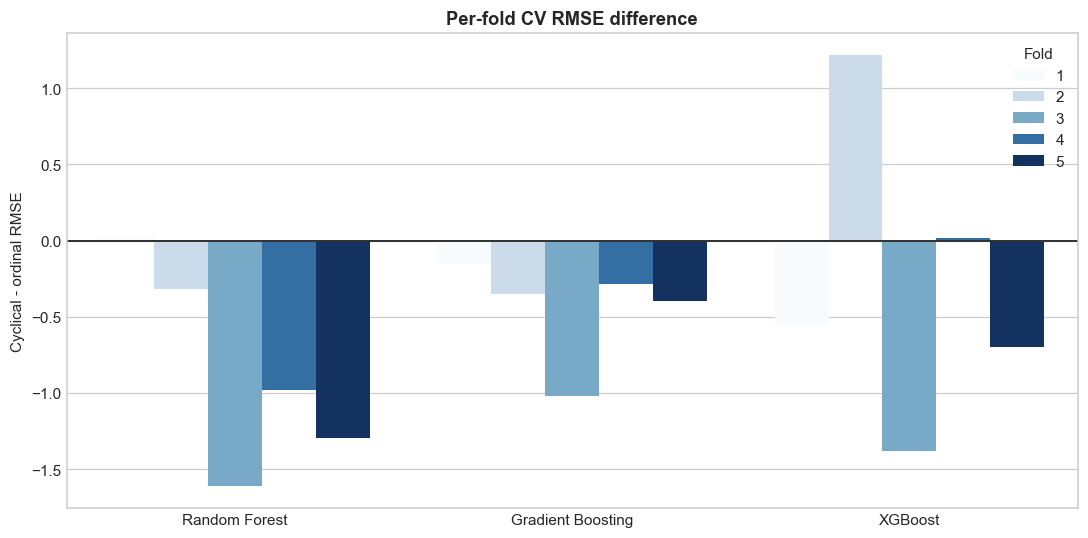

                    mean    std
Model                          
Gradient Boosting -0.440  0.337
Random Forest     -0.838  0.678
XGBoost           -0.280  0.974
Negative = cyclical encoding is better on that fold; positive = ordinal encoding is better.


In [37]:
# Per-fold CV difference: cyclical RMSE minus ordinal RMSE
fold_difference_rows = []
for model in ["Random Forest", "Gradient Boosting", "XGBoost"]:
    cyc_folds = np.asarray(cv_folds[model])
    ord_folds = np.asarray(ordinal_cv[model])
    for fold, delta in enumerate(cyc_folds - ord_folds, start=1):
        fold_difference_rows.append({"Model": model, "Fold": fold, "Cyclical - ordinal RMSE": delta})
fold_difference = pd.DataFrame(fold_difference_rows)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=fold_difference, x="Model", y="Cyclical - ordinal RMSE", hue="Fold",
            palette="Blues", ax=ax)
ax.axhline(0, color="#333333", lw=1.3)
ax.set_title("Per-fold CV RMSE difference")
ax.set_xlabel("")
ax.set_ylabel("Cyclical - ordinal RMSE")
plt.tight_layout()
plt.show()

print(fold_difference.groupby("Model")["Cyclical - ordinal RMSE"].agg(["mean", "std"]).round(3).to_string())
print("Negative = cyclical encoding is better on that fold; positive = ordinal encoding is better.")


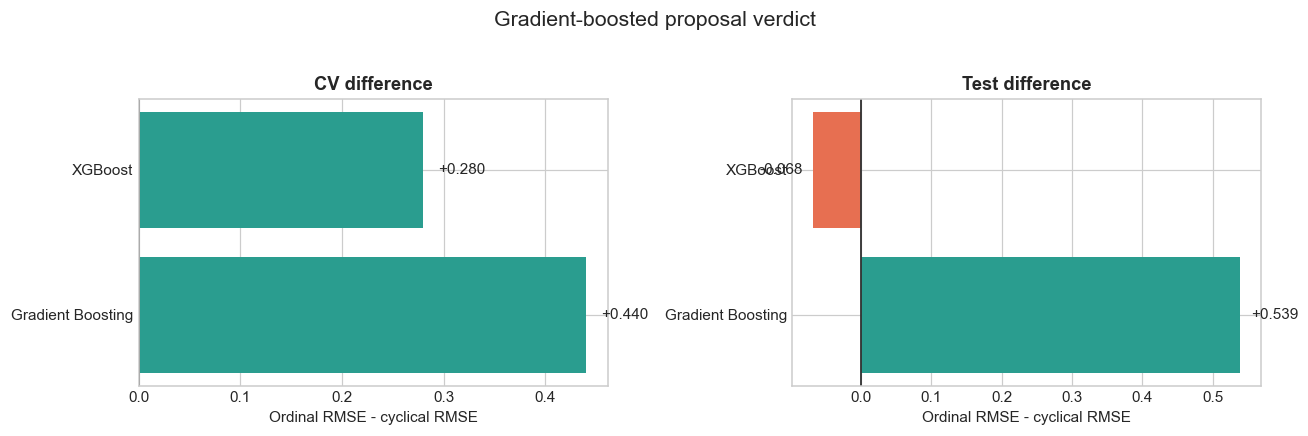

In [38]:
# Focused verdict on the two gradient-boosted pipelines
boosting_models = ["Gradient Boosting", "XGBoost"]
boosting_diff = rmse_difference.loc[boosting_models]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, column in zip(axes, ["CV difference", "Test difference"]):
    values = boosting_diff[column]
    colors = ["#2a9d8f" if v > 0 else "#e76f51" for v in values]
    ax.barh(values.index, values.values, color=colors)
    ax.axvline(0, color="#333333", lw=1.2)
    ax.set_xlabel("Ordinal RMSE - cyclical RMSE")
    ax.set_title(column)
    for y, v in enumerate(values.values):
        ax.text(v + (0.015 if v >= 0 else -0.015), y, f"{v:+.3f}",
                va="center", ha="left" if v >= 0 else "right", fontsize=10)
plt.suptitle("Gradient-boosted proposal verdict", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()


### 12.1 Proposal conclusion

**Verdict: the result is mixed, so the proposal is not supported uniformly across gradient-boosted pipelines.**

- **Gradient Boosting:** cyclical encoding wins - test RMSE 38.021 versus 38.560 for ordinal (0.539 lower).
- **XGBoost:** ordinal encoding wins slightly - test RMSE 37.313 versus 37.381 for cyclical (0.068 lower).
- On CV RMSE, both boosting models favor cyclical encoding: Gradient Boosting 39.719 versus 40.158; XGBoost 38.819 versus 39.099.
- Random Forest and Linear Regression also favor the engineered representation on test RMSE, with improvements of 0.793 and 41.845 respectively.

The proposal is supported by CV for both gradient boosters, but the held-out test result is model-dependent. The XGBoost advantage for ordinal encoding is small (0.068 RMSE), while Gradient Boosting provides the clearer cyclical benefit.


## 13. Trying with Optuna

As a small curiosity check, Optuna tunes the same four models with Bayesian/TPE search. The protocol remains identical: five-fold shuffled CV, CV RMSE as the objective, and the held-out test set only for final evaluation. The trial budget is deliberately modest and should be read as an exploratory comparison rather than a full optimization run.

In [41]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
OPTUNA_TRIALS = 15

In [42]:
def make_optuna_estimator(name, trial):
    if name == "Linear Regression":
        return LinearRegression(
            fit_intercept=trial.suggest_categorical("fit_intercept", [True, False]),
            positive=trial.suggest_categorical("positive", [False, True]),
        )
    if name == "Random Forest":
        return RandomForestRegressor(
            n_estimators=trial.suggest_int("n_estimators", 100, 300, step=50),
            max_depth=trial.suggest_categorical("max_depth", [10, 15, 20, 25, 30, None]),
            min_samples_split=trial.suggest_categorical("min_samples_split", [2, 5, 10]),
            min_samples_leaf=trial.suggest_categorical("min_samples_leaf", [1, 2, 4]),
            max_features=trial.suggest_categorical("max_features", ["sqrt", 0.7, 1.0]),
            random_state=SEED,
            n_jobs=1,
        )
    if name == "Gradient Boosting":
        return GradientBoostingRegressor(
            n_estimators=trial.suggest_int("n_estimators", 150, 500, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.03, 0.10, log=True),
            max_depth=trial.suggest_int("max_depth", 3, 6),
            subsample=trial.suggest_float("subsample", 0.70, 1.00),
            min_samples_leaf=trial.suggest_categorical("min_samples_leaf", [1, 3, 5]),
            random_state=SEED,
        )
    return XGBRegressor(
        objective="reg:squarederror",
        n_estimators=trial.suggest_int("n_estimators", 300, 700, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.03, 0.10, log=True),
        max_depth=trial.suggest_int("max_depth", 4, 7),
        subsample=trial.suggest_float("subsample", 0.70, 1.00),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.70, 1.00),
        reg_lambda=trial.suggest_float("reg_lambda", 1.0, 5.0, log=True),
        random_state=SEED,
        n_jobs=1,
    )


optuna_studies, optuna_pipes, optuna_rows = {}, {}, []
optuna_elapsed = {}

for model_name in ["Linear Regression", "Random Forest", "Gradient Boosting", "XGBoost"]:
    t0 = time.time()
    study = optuna.create_study(
        direction="minimize",
        study_name=f"{model_name} CV RMSE",
        sampler=optuna.samplers.TPESampler(seed=SEED),
    )

    def objective(trial, model_name=model_name):
        estimator = make_optuna_estimator(model_name, trial)
        pipe = make_pipeline(estimator)
        return -cross_val_score(pipe, X_train, y_train, cv=cv,
                                scoring=RMSE, n_jobs=-1).mean()

    study.optimize(objective, n_trials=OPTUNA_TRIALS, show_progress_bar=False)
    optuna_elapsed[model_name] = time.time() - t0
    optuna_studies[model_name] = study

    params = study.best_params
    if model_name == "Linear Regression":
        best_estimator = LinearRegression(**params)
    elif model_name == "Random Forest":
        best_estimator = RandomForestRegressor(**params, random_state=SEED, n_jobs=1)
    elif model_name == "Gradient Boosting":
        best_estimator = GradientBoostingRegressor(**params, random_state=SEED)
    else:
        best_estimator = XGBRegressor(**params, objective="reg:squarederror", random_state=SEED, n_jobs=1)
    best_pipe = make_pipeline(best_estimator).fit(X_train, y_train)
    optuna_pipes[model_name] = best_pipe
    pred = best_pipe.predict(X_test)
    optuna_rows.append({
        "Model": model_name,
        "Optuna CV RMSE": study.best_value,
        "Optuna Test RMSE": root_mean_squared_error(y_test, pred),
        "Optuna Test MAE": mean_absolute_error(y_test, pred),
        "Optuna Test R2": r2_score(y_test, pred),
        "Optuna Test MAPE (%)": mean_absolute_percentage_error(y_test, pred) * 100,
        "Optuna trials": OPTUNA_TRIALS,
        "Optuna time (s)": optuna_elapsed[model_name],
    })

optuna_comparison = pd.DataFrame(optuna_rows).sort_values("Optuna CV RMSE").reset_index(drop=True)
optuna_comparison.to_csv(REPORTS / "optuna_model_comparison.csv", index=False)
display(optuna_comparison.round(3))

,Model,Optuna CV RMSE,Optuna Test RMSE,Optuna Test MAE,Optuna Test R2,Optuna Test MAPE (%),Optuna trials,Optuna time (s)
0,XGBoost,39.210,37.440,22.469,0.956,32.670,15,20.278
1,Gradient Boosting,40.236,38.301,23.484,0.954,36.419,15,102.027
2,Random Forest,42.355,40.223,24.163,0.949,31.374,15,93.955
3,Linear Regression,100.584,97.366,72.498,0.701,261.859,15,15.180


### 13.1 Optuna vs GridSearch and the proposal

The table below compares Optuna with the existing GridSearchCV/RandomizedSearchCV results. A negative CV or test difference means Optuna improved RMSE; a positive difference means the existing grid-based search was better.

,Model,Optuna CV RMSE,Grid CV RMSE,Optuna - Grid CV RMSE,Optuna Test RMSE,Proposal cyclical Test RMSE,Proposal ordinal Test RMSE,Optuna - proposal cyclical Test RMSE,Optuna Test R2
0,XGBoost,39.210,38.819,0.390,37.440,37.381,37.313,0.059,0.956
1,Gradient Boosting,40.236,39.719,0.518,38.301,38.021,38.560,0.280,0.954
2,Random Forest,42.355,42.171,0.184,40.223,39.896,40.689,0.328,0.949
3,Linear Regression,100.584,100.584,0.000,97.366,97.366,139.211,0.000,0.701


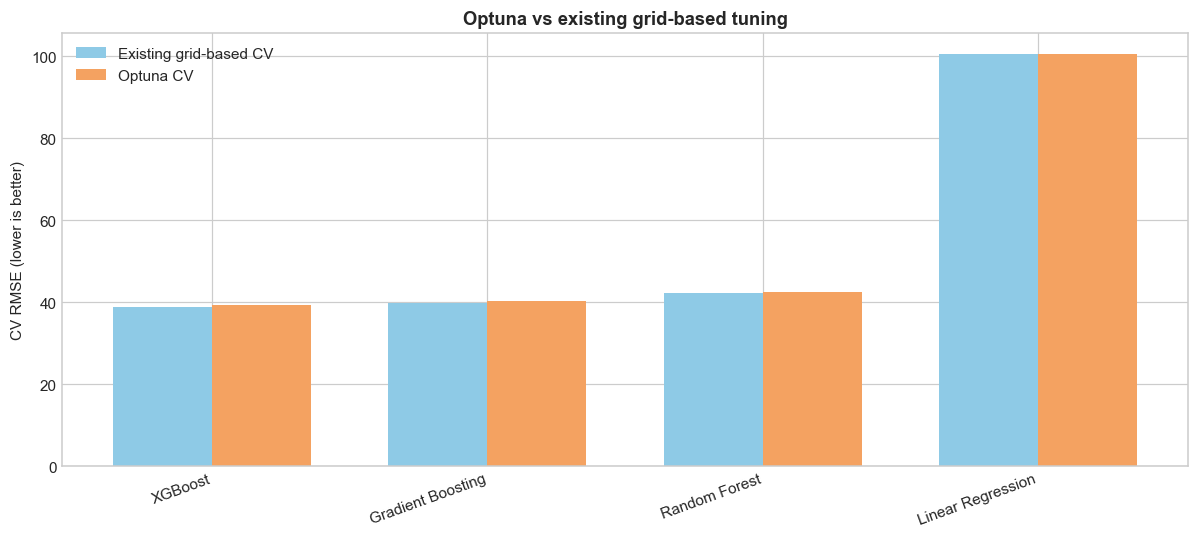

In [43]:
grid_rows = [{
    "Model": name,
    "Grid CV RMSE": tuned[name]["post"],
} for name in ["Random Forest", "Gradient Boosting", "XGBoost"]]
grid_rows.append({"Model": "Linear Regression", "Grid CV RMSE": comparison.set_index("Model").loc["Linear Regression", "CV RMSE"]})

comparison_13 = optuna_comparison.merge(pd.DataFrame(grid_rows), on="Model", how="left")
comparison_13["Optuna - Grid CV RMSE"] = comparison_13["Optuna CV RMSE"] - comparison_13["Grid CV RMSE"]

proposal_table = proposal_comparison.pivot(index="Model", columns="Representation", values=["CV RMSE", "Test RMSE"])
proposal_rows = []
for _, row in comparison_13.iterrows():
    model = row["Model"]
    if model in proposal_table.index:
        proposal_rows.append({
            "Model": model,
            "Proposal cyclical CV RMSE": proposal_table.loc[model, ("CV RMSE", "Cyclical / engineered")],
            "Proposal ordinal CV RMSE": proposal_table.loc[model, ("CV RMSE", "Ordinal integers")],
            "Proposal cyclical Test RMSE": proposal_table.loc[model, ("Test RMSE", "Cyclical / engineered")],
            "Proposal ordinal Test RMSE": proposal_table.loc[model, ("Test RMSE", "Ordinal integers")],
        })

comparison_13 = comparison_13.merge(pd.DataFrame(proposal_rows), on="Model", how="left")
comparison_13["Optuna - proposal cyclical Test RMSE"] = (
    comparison_13["Optuna Test RMSE"] - comparison_13["Proposal cyclical Test RMSE"]
)

display(comparison_13[[
    "Model", "Optuna CV RMSE", "Grid CV RMSE", "Optuna - Grid CV RMSE",
    "Optuna Test RMSE", "Proposal cyclical Test RMSE", "Proposal ordinal Test RMSE",
    "Optuna - proposal cyclical Test RMSE", "Optuna Test R2",
]].round(3))

fig, ax = plt.subplots(figsize=(11, 5))
plot_names = comparison_13["Model"].tolist()
x = np.arange(len(plot_names))
ax.bar(x - 0.18, comparison_13["Grid CV RMSE"], width=0.36, label="Existing grid-based CV", color="#8ecae6")
ax.bar(x + 0.18, comparison_13["Optuna CV RMSE"], width=0.36, label="Optuna CV", color="#f4a261")
ax.set_xticks(x, plot_names, rotation=20, ha="right")
ax.set_ylabel("CV RMSE (lower is better)")
ax.set_title("Optuna vs existing grid-based tuning")
ax.legend()
plt.tight_layout(); plt.show()

**Brief verdict:**

- **XGBoost wins across both searches:** its Optuna run reached **39.210 CV RMSE / 37.440 test RMSE**, versus 38.819 / 37.381 for the existing grid-based configuration.
- **Gradient Boosting:** Optuna reached 40.236 CV RMSE and 38.301 test RMSE, versus 39.719 and 38.021 for GridSearch.
- **Random Forest:** Optuna reached 42.355 CV RMSE and 40.223 test RMSE, versus 42.171 and 39.896 for GridSearch.
- **Linear Regression** remained unchanged at 100.584 CV RMSE / 97.366 test RMSE.
- Thus, the grid-based search was slightly better on CV and held-out RMSE for all three tunable models in this small run. The gains are small enough that a larger Optuna budget may change the ranking.
- For the proposal, the pattern also stayed model-dependent: Optuna kept Gradient Boosting and Random Forest close to their cyclic-grid results, while XGBoost remained the better of the two boosting families. The prior §12 mixed cyclical/ordinal verdict is unchanged.

Because Optuna is stochastic and this run uses a small trial budget, repeated seeds or more trials are needed before making a robust production recommendation.